# Прогноз почасового спроса на велопрокат

Capital Bikeshare, 2011–2012 годы. Задача — оценить число аренд в каждый час следующих суток или недели. Последовательно покажите данные, план проверки, сравнение моделей и надёжность прогноза. Ячейки читают сохранённые результаты. [Описание проекта](docs/README.md)

In [1]:
from pathlib import Path, PureWindowsPath
import json
import pandas as pd
import yaml
from IPython.display import display, Markdown, Image

PROFILE = 'full'
cwd = Path.cwd()
root = next(path for path in (cwd, *cwd.parents) if (path / "configs/study.yaml").is_file())
pointer = json.loads((root / "artifacts" / f"latest_{PROFILE}.json").read_text(encoding="utf-8"))
folder = root.joinpath(*PureWindowsPath(pointer["path"]).parts)
status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
config = yaml.safe_load((folder / "resolved.yaml").read_text(encoding="utf-8"))

def show_figure(name):
    path = folder / "figures" / name
    if path.is_file():
        display(Image(filename=str(path)))

if PROFILE == "smoke":
    message = "Короткая проверка на одном окне каждого этапа."
elif status.get("course_complete"):
    message = "Полное исследование завершено."
else:
    message = "Полное исследование продолжается. Ниже доступны EDA и сохранённые результаты валидации."
display(Markdown(f"**Статус прогона** · {message}"))

**Статус прогона** · Полное исследование завершено.

## 1. Данные и предварительный анализ

В строке один час. Прогнозируем столбец `y` — общее число аренд. После восстановления часовой сетки сохраняем признак наличия факта `observed`. Посмотрите на утренний и вечерний пики и пики автокорреляции на лагах 24 и 168. Они объясняют, почему проверяем суточную и недельную сезонности.

,ds,y,observed
0,2011-01-01 00:00:00,16.0,True
1,2011-01-01 01:00:00,40.0,True
2,2011-01-01 02:00:00,32.0,True
3,2011-01-01 03:00:00,13.0,True
4,2011-01-01 04:00:00,1.0,True


Часов в сетке: 17544. Наблюдаемых: 17379. Пропущено: 165.


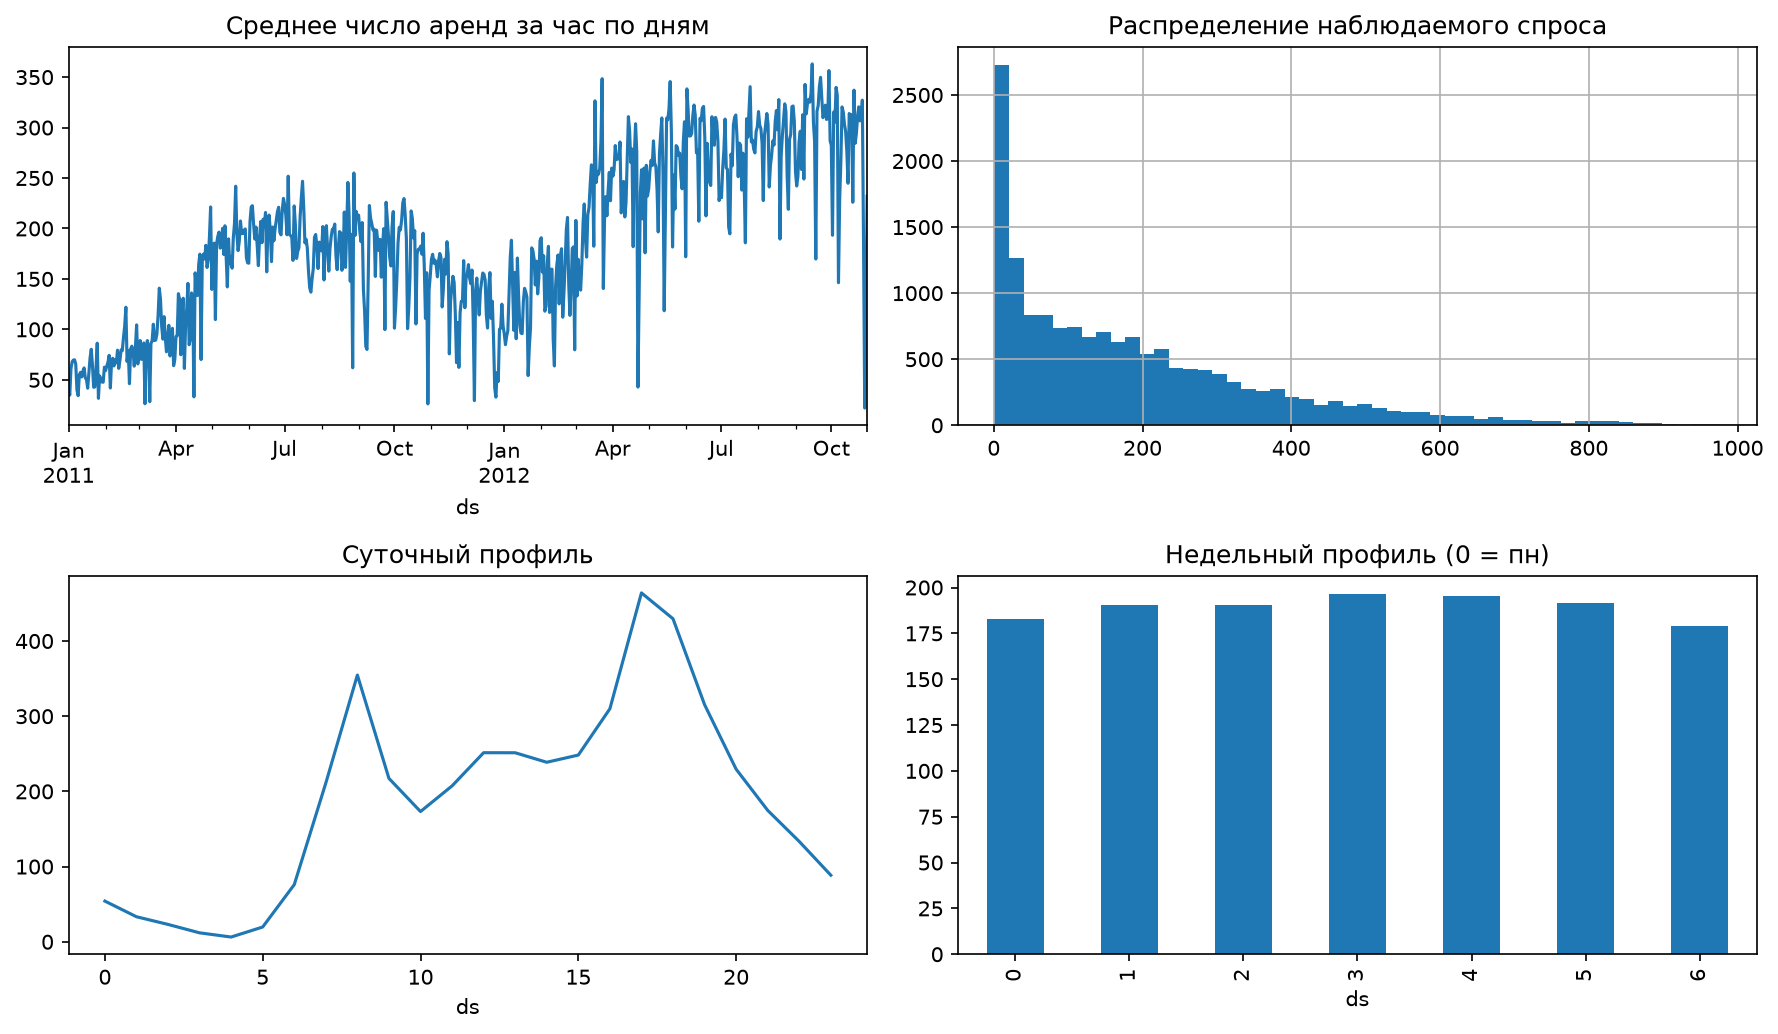

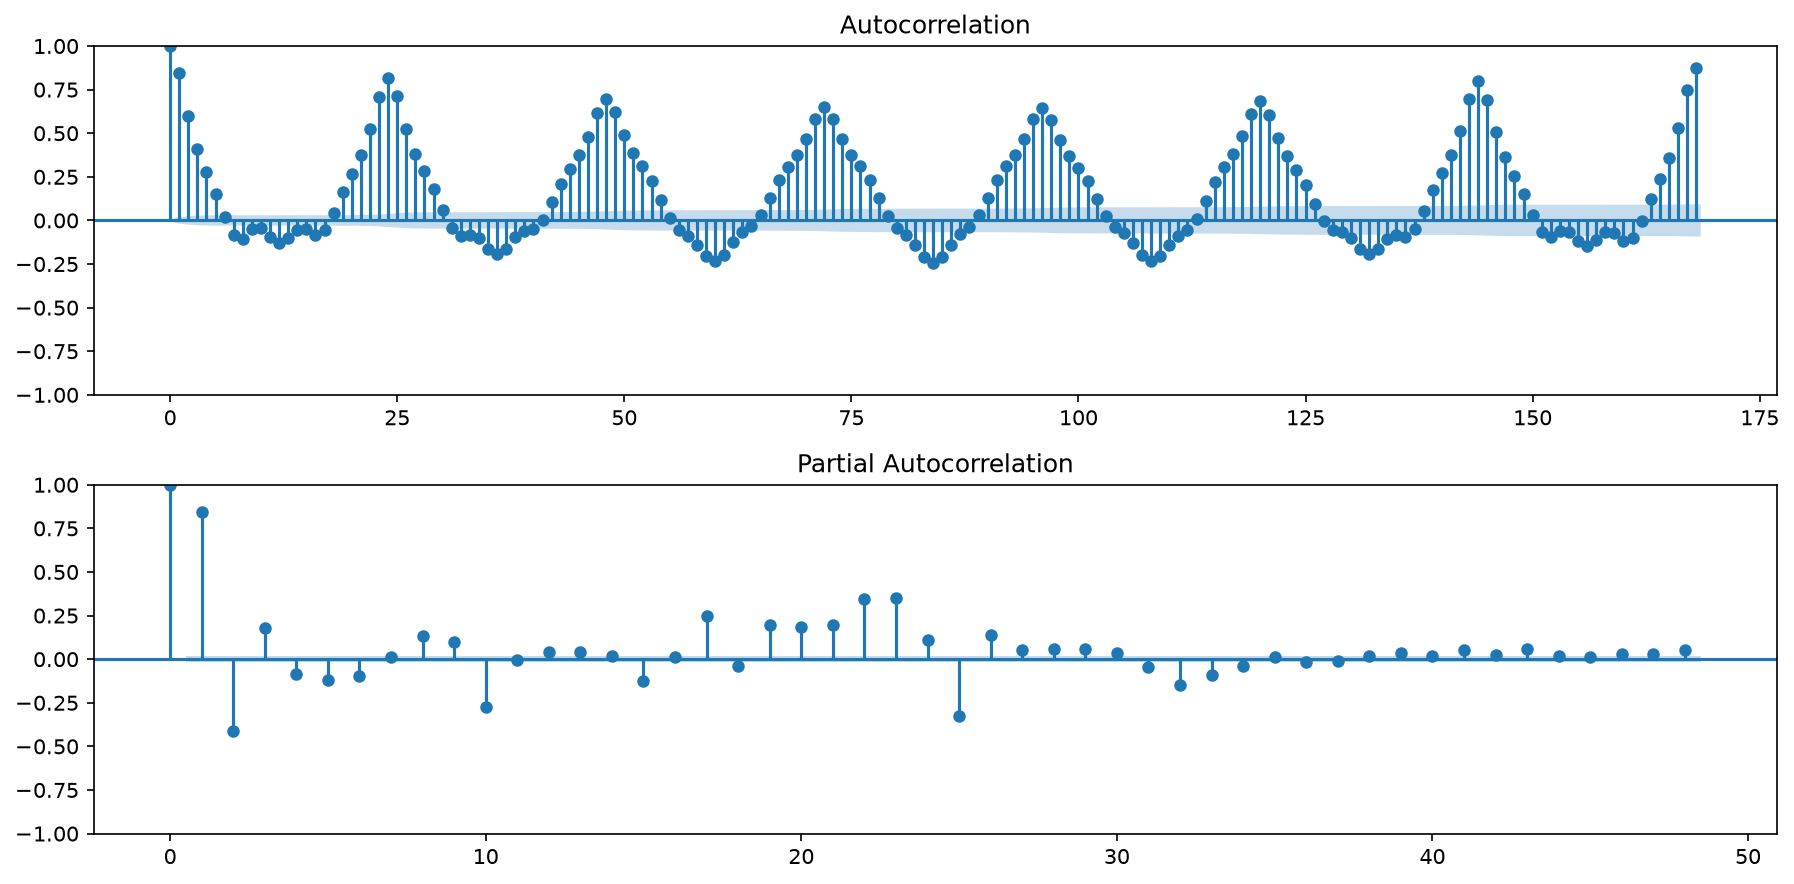

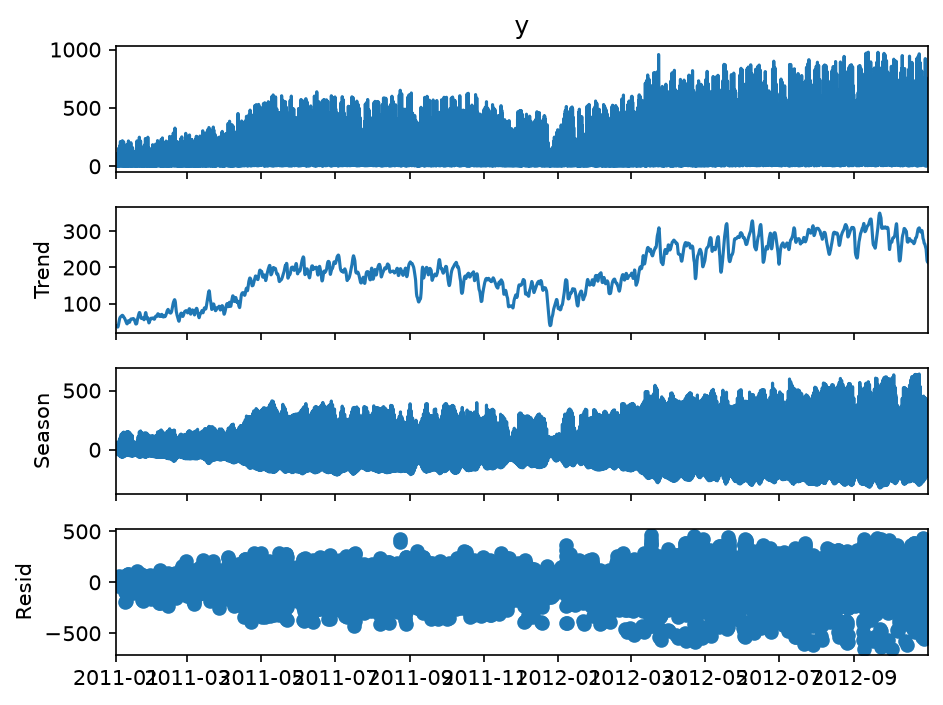

In [2]:
hourly = pd.read_csv(root / "data/processed/hourly.csv")
display(hourly[["ds", "y", "observed"]].head())
print(f"Часов в сетке: {len(hourly)}. Наблюдаемых: {hourly.observed.sum()}. "
      f"Пропущено: {(~hourly.observed).sum()}.")
for name in ("eda.png", "acf_pacf.png", "decomposition.png"):
    show_figure(name)

## 2. Временная проверка и статистические модели

Каждая дата ниже — первая точка прогноза. Для неё модель обучается на всех доступных часах до начала окна в полном профиле. Валидация нужна, чтобы выбрать настройки, например сезонность 24 или 168 часов. Ноябрьские прогнозы используются для калибровки интервалов, декабрьские — для итоговой проверки.

**Бейзлайн** берёт спрос того же часа неделю назад. **Статистические методы** — ARIMA, ETS, Theta, CES и MSTL. Сравниваем также AutoARIMA и AutoETS с ручными вариантами.

**MAE** показывает средний размер промаха в арендах за час. Меньшее число соответствует меньшей ошибке на одинаковых окнах.

In [3]:
phase_labels = {"validation": "Валидация", "calibration": "Калибровка", "test": "Тест"}
display(pd.DataFrame({phase_labels[phase]: origins for phase, origins in config["splits"].items()}))

summary_path = folder / "summary.csv"
if summary_path.is_file():
    scores = pd.read_csv(summary_path)
else:
    scores = pd.DataFrame()
    selected_path = folder / "selected.json"
    if selected_path.is_file():
        selected = json.loads(selected_path.read_text(encoding="utf-8"))
        validation = []
        for path in (folder / "jobs").glob("*/result.json"):
            row = json.loads(path.read_text(encoding="utf-8"))
            setting = selected.get(str(row["horizon"]), {}).get(row["model"])
            if row["status"] == "ok" and row["phase"] == "validation" and row["params"] == setting:
                validation.append(row)
        if validation:
            scores = (pd.DataFrame(validation)
                      .groupby(["phase", "group", "model", "horizon"], as_index=False)
                      [["MAE", "fit_seconds", "predict_seconds"]].mean())

def show_scores(groups):
    if scores.empty:
        print("Сводка появится после подбора настроек.")
        return
    part = scores[scores.group.isin(groups) & scores.phase.isin(["validation", "test"])]
    columns = {"phase": "Этап", "horizon": "Горизонт, ч", "model": "Модель",
               "MAE": "MAE", "fit_seconds": "Обучение, с", "predict_seconds": "Прогноз, с"}
    part = part.sort_values(["horizon", "phase", "MAE"])[list(columns)].round(3).rename(columns=columns)
    part["Этап"] = part["Этап"].map(phase_labels)
    display(part.reset_index(drop=True))

show_scores(["baseline", "statistical"])

,Валидация,Калибровка,Тест
0,2012-09-01,2012-11-01,2012-12-01
1,2012-09-15,2012-11-08,2012-12-08
2,2012-10-01,2012-11-15,2012-12-15
3,2012-10-15,2012-11-22,2012-12-22


,Этап,"Горизонт, ч",Модель,MAE,"Обучение, с","Прогноз, с"
0,Тест,24,Theta,22.697,7.425,0.002
1,Тест,24,MSTL,42.076,3.313,0.002
2,Тест,24,AutoETS,50.324,151.251,0.001
3,Тест,24,ARIMA,56.438,7.126,0.005
4,Тест,24,ETS,56.566,7.526,0.001
5,Тест,24,AutoARIMA,76.734,237.655,0.005
6,Тест,24,CES,78.737,2.384,0.001
7,Тест,24,SeasonalNaive,78.917,0.002,0.001
8,Валидация,24,AutoETS,47.031,138.886,0.002
9,Валидация,24,CES,57.469,2.080,0.002


## 3. Машинное и глубокое обучение

**Машинное обучение** — Ridge, случайный лес и градиентный бустинг. Модели используют прошлый спрос, скользящие статистики и календарь. **Нейросети** — MLP, LSTM и NHITS. У них сравниваются входные истории разной длины. Результаты ниже помогают понять, где выигрыш в точности оправдывает время обучения.

In [4]:
show_scores(["ML", "DL"])

,Этап,"Горизонт, ч",Модель,MAE,"Обучение, с","Прогноз, с"
0,Тест,24,NHITS,38.990,6.023,0.019
1,Тест,24,MLP,46.589,3.770,0.018
2,Тест,24,LSTM,50.234,4.286,0.015
3,Тест,24,RandomForestRegressor,54.738,2.999,0.548
4,Тест,24,HistGradientBoostingRegressor,54.827,0.306,0.054
5,Тест,24,Ridge,73.318,0.033,0.033
6,Валидация,24,NHITS,44.195,6.299,0.019
7,Валидация,24,MLP,47.894,3.826,0.017
8,Валидация,24,RandomForestRegressor,51.130,2.641,0.573
9,Валидация,24,HistGradientBoostingRegressor,52.589,0.349,0.059


## 4. Итоговая точность, интервалы и пайплайн

Подготовка данных → подбор настроек → калибровка → итоговая проверка → отчёт. Сравните MAE выбранной на валидации модели с недельным бейзлайном. Полоса на графике — прогнозный интервал. В таблице приведены его фактическое покрытие и ширина.

,"Горизонт, ч",Выбор по валидации,MAE модели на тесте,MAE бейзлайна на тесте,"Покрытие 95%-го интервала, %",Средняя ширина
0,24,NHITS,38.99,78.92,100.00,325.50
1,168,LSTM,61.70,68.23,95.18,395.98


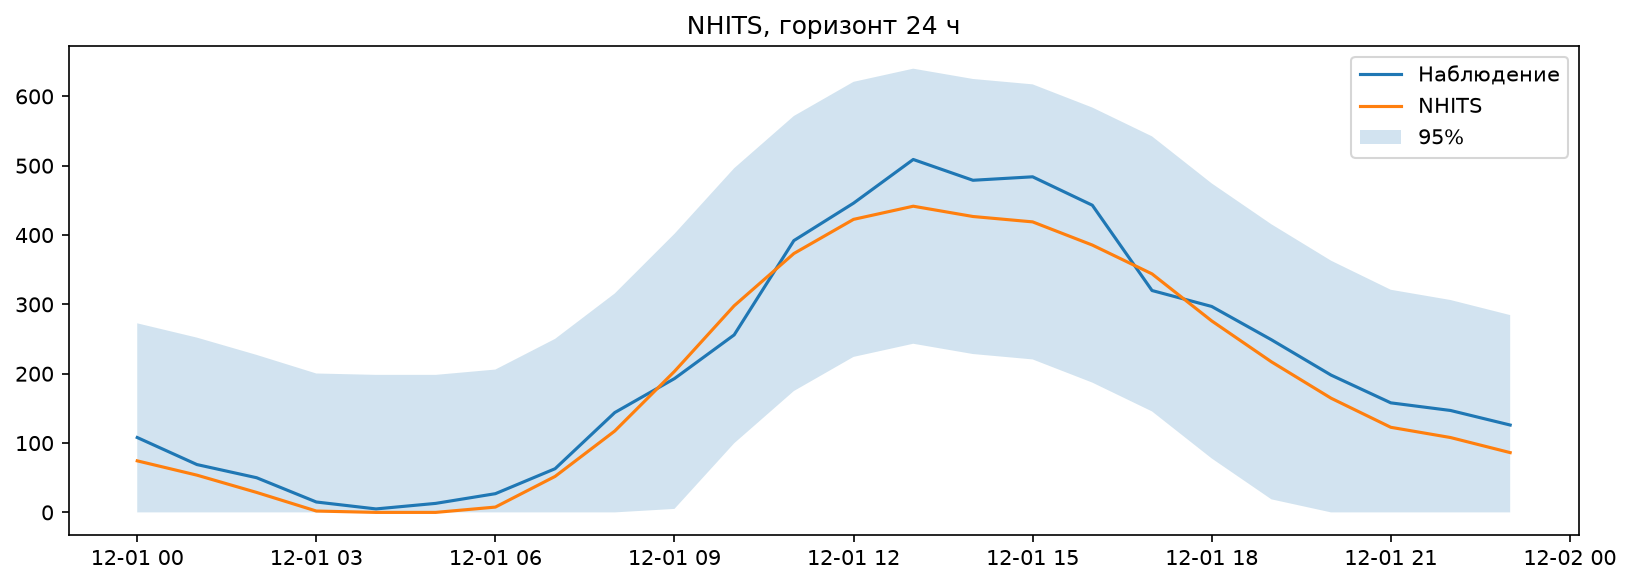

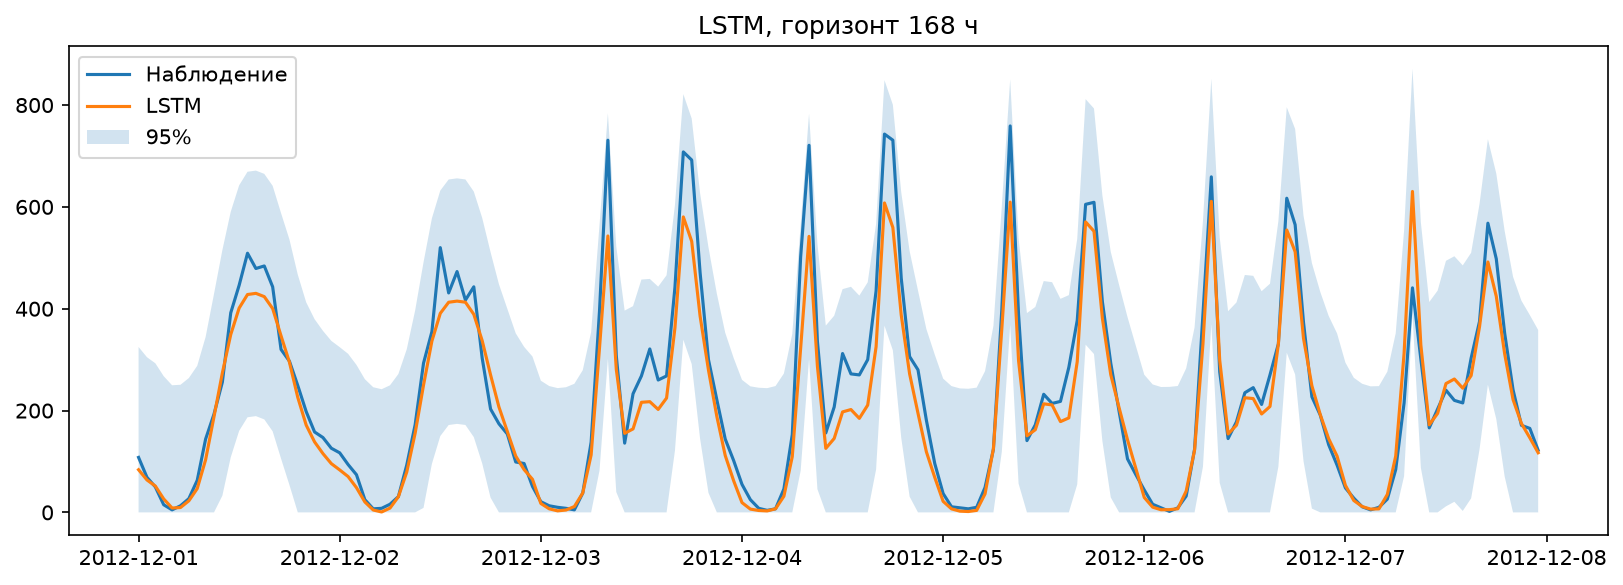

[Полный отчёт этого прогона](artifacts/full/REPORT.md)

In [5]:
coverage_path = folder / "coverage_by_window.csv"
if scores.empty or "test" not in set(scores.phase) or not coverage_path.is_file():
    print("Декабрьские метрики и прогнозные интервалы появятся после полного прогона.")
else:
    coverage = pd.read_csv(coverage_path)
    comparison = []
    for h, validation in scores[scores.phase == "validation"].groupby("horizon"):
        leader = validation.sort_values(["MAE", "model"]).iloc[0].model
        tested = scores[(scores.horizon == h) & (scores.phase == "test")].set_index("model")
        if leader not in tested.index or "SeasonalNaive" not in tested.index:
            continue
        intervals = coverage[(coverage.horizon == h) & (coverage.model == leader)
                             & (coverage.level == 0.95)]
        comparison.append({"Горизонт, ч": h, "Выбор по валидации": leader,
                           "MAE модели на тесте": tested.loc[leader, "MAE"],
                           "MAE бейзлайна на тесте": tested.loc["SeasonalNaive", "MAE"],
                           "Покрытие 95%-го интервала, %": 100 * intervals.coverage.mean(),
                           "Средняя ширина": intervals.mean_width.mean()})
    if comparison:
        display(pd.DataFrame(comparison).round(2))
        for row in comparison:
            h = row["Горизонт, ч"]
            show_figure(f"forecast_{row['Выбор по валидации']}_{h}.png")
if (folder / "REPORT.md").is_file():
    report = (folder / "REPORT.md").relative_to(root).as_posix()
    display(Markdown(f"[Полный отчёт этого прогона]({report})"))